# Truss topology optimisation by member removal with a stress constraint (Q-learning)

Starting from the ground structure, the agent removes one member at a time.

**Problem:** minimise volume  subject to  max |σ| ≤ σ_lim  and a stable truss.

- **State:** 0/1 for every member of the ground structure.
- **Action:** remove one member that is still present. If a removal leaves a free, unloaded node with a single member, that member is removed too.
- **Reward:** fraction of the ground-structure volume saved. A removal that breaks the stress limit or makes the truss unstable is rejected: it gets a small penalty, the design stays as it was and the episode ends.
- **Learning:** tabular Q-learning, γ = 1, with ε (0.9 → 0.01) and α (1 → 0.1) decayed by a cosine. The Q-table grows as new states are met (Yusuf 2023, Ch. 3).

In [1]:
import sys
sys.path.append(r"D:\Book Store\M.Tech\M.Tech Thesis\Truss Topology Optimisation")

import numpy as np
import matplotlib.pyplot as plt
from src.ground_structure import generate_ground_structure, index_to_state
from src.valid_and_stable import plot_truss, check_stability, get_displacements

import gymnasium as gym
from gymnasium import spaces

Number of Nodes: 6
Number of Bars: 13


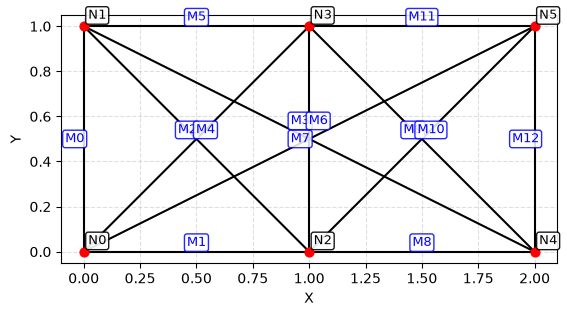

In [2]:
grid = (2, 1)
nodes, ground_structure_bars = generate_ground_structure(grid)

E = 2.1e11  # N/m2
A = 40      # cm2
fixed = np.array([0, 1, 2, 3])
dofs = np.array([i for i in range(2*len(nodes)) if i not in fixed])

f0 = 1e5    # N
ff = np.zeros((2*len(nodes), 1))
ff[7] = -f0

disp_dof  = 9       # dof whose displacement is reported (node 4, y-direction)
sigma_lim = 25.0    # MPa  <-- stress limit (tension and compression), change this

print(f"Number of Nodes: {len(nodes)}")
print(f"Number of Bars: {len(ground_structure_bars)}")
plot_truss(nodes, ground_structure_bars)
plt.show()

In [3]:
def get_stresses(nodes, bars, A, E, ff, dofs):
    # Axial stress of every bar in MPa (tension +), from the nodal displacements
    u = get_displacements(nodes, bars, A, E, ff, dofs, all=True)[:, 0] * 1e-3   # m
    delta = nodes[bars[:, 1]] - nodes[bars[:, 0]]
    L = np.linalg.norm(delta, axis=1)
    c = delta / L[:, None]
    du = u.reshape(-1, 2)[bars[:, 1]] - u.reshape(-1, 2)[bars[:, 0]]
    return E * (c * du).sum(axis=1) / L / 1e6

In [4]:
sigma_gs = get_stresses(nodes, ground_structure_bars, A, E, ff, dofs)
for k, ((i, j), s) in enumerate(zip(ground_structure_bars, sigma_gs)):
    print(f"M{k:<3} N{i}-N{j}   sigma = {s:9.3f} MPa")
print(f"\nGround structure: max |sigma| = {np.abs(sigma_gs).max():.3f} MPa, "
      f"u at dof {disp_dof} = {get_displacements(nodes, ground_structure_bars, A, E, ff, dofs, disp_at=disp_dof):.4f} mm")

M0   N0-N1   sigma =     0.000 MPa
M1   N0-N2   sigma =    -9.147 MPa
M2   N0-N3   sigma =   -16.117 MPa
M3   N0-N5   sigma =    -4.983 MPa
M4   N1-N2   sigma =    12.052 MPa
M5   N1-N3   sigma =    10.772 MPa
M6   N1-N4   sigma =     6.379 MPa
M7   N2-N3   sigma =    -9.756 MPa
M8   N2-N4   sigma =    -1.857 MPa
M9   N2-N5   sigma =     1.744 MPa
M10  N3-N4   sigma =    -5.441 MPa
M11  N3-N5   sigma =     3.223 MPa
M12  N4-N5   sigma =     0.995 MPa

Ground structure: max |sigma| = 16.117 MPa, u at dof 9 = -0.2567 mm


In [5]:
class TrussStressEnv(gym.Env):
    metadata = {"render_modes": ["human"]}

    def __init__(self, nodes, bars, dofs, A, E, ff, sigma_lim, disp_dof, penalty=0.1, render_mode=None):
        super().__init__()

        self.nodes = nodes.astype(float)
        self.bars = bars.astype(int)           # ground structure, member id = row index (M0, M1, ...)
        self.dofs = np.asarray(dofs).astype(int)
        self.A = A
        self.E = E
        self.ff = ff
        self.sigma_lim = sigma_lim
        self.disp_dof = disp_dof
        self.penalty = penalty
        self.n_bars = len(self.bars)

        self.action_space = spaces.Discrete(self.n_bars)
        self.observation_space = spaces.MultiBinary(self.n_bars)

        L = np.linalg.norm(self.nodes[self.bars[:, 1]] - self.nodes[self.bars[:, 0]], axis=1)
        self.bar_vol = self.A * 1e-4 * L       # m3 of each member
        self.V0 = self.bar_vol.sum()

        # Nodes that must stay: loaded nodes and the node of disp_dof
        loaded = np.where(np.abs(self.ff[:, 0]) > 0)[0] // 2
        self.keep_nodes = set(loaded.tolist()) | {self.disp_dof // 2}
        # Fully free nodes (no support)
        self.free_nodes = {k for k in range(len(self.nodes)) if 2*k in self.dofs and 2*k + 1 in self.dofs}

        self.cache = {}                        # FE result of every configuration already analysed
        self.render_mode = render_mode
        self.state = None

    def analyse(self, state):
        # Returns (stable, max |sigma| in MPa, member with max |sigma|, u at disp_dof in mm)
        key = state.tobytes()
        if key not in self.cache:
            ids = np.where(state == 1)[0]
            bars = self.bars[ids]
            active_nodes = set(bars.ravel().tolist())
            result = (False, np.nan, None, np.nan)
            if self.keep_nodes <= active_nodes:
                dofs = np.array([d for d in self.dofs if d // 2 in active_nodes])
                if check_stability(self.nodes, bars, dofs, self.A, self.E, self.ff):
                    sigma = get_stresses(self.nodes, bars, self.A, self.E, self.ff, dofs)
                    k = np.argmax(np.abs(sigma))
                    u = get_displacements(self.nodes, bars, self.A, self.E, self.ff, dofs, disp_at=self.disp_dof)
                    result = (True, abs(sigma[k]), ids[k], u)
            self.cache[key] = result
        return self.cache[key]

    def remove_dangling(self, state):
        # A free, unloaded node left with a single member is removed together with that member
        pruned = []
        while True:
            bars = self.bars[state == 1]
            deg = np.bincount(bars.ravel(), minlength=len(self.nodes))
            dangling = [k for k in self.free_nodes - self.keep_nodes if deg[k] == 1]
            if not dangling:
                return state, pruned
            for k in dangling:
                m = np.where((state == 1) & ((self.bars[:, 0] == k) | (self.bars[:, 1] == k)))[0]
                state[m] = 0
                pruned += m.tolist()

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.state = np.ones(self.n_bars, dtype=int)
        return self.state.copy(), {}

    def step(self, action):
        new_state = self.state.copy()
        new_state[action] = 0
        new_state, pruned = self.remove_dangling(new_state)
        stable, s_max, k_max, u = self.analyse(new_state)
        info = {"stable": stable, "sigma_max": s_max, "member_max": k_max, "u": u, "pruned": pruned}

        if not stable or s_max > self.sigma_lim:
            # Constraint violated: removal rejected, design stays as it was, episode ends
            return self.state.copy(), -self.penalty, True, False, info

        removed = self.state - new_state
        reward = self.bar_vol[removed == 1].sum() / self.V0
        self.state = new_state
        return self.state.copy(), reward, False, False, info

    def render(self):
        if self.render_mode == "human":
            plot_truss(self.nodes, self.bars[self.state == 1], show_member_ids=False)

In [6]:
def cosine_decay(m, C, B, floor):
    # eps_m = C cos(B m), held at `floor` once it gets there
    return max(floor, C * np.cos(B * m)) if B * m < np.pi / 2 else floor


def train_TSE(env, episodes=3000, gamma=1.0, decay_frac=0.7, print_every=500, seed=None):
    rng = np.random.default_rng(seed)

    # epsilon (0.9 -> 0.01) and alpha (1 -> 0.1) reach their floors after decay_frac*episodes
    B_eps = np.arccos(0.01 / 0.9) / (decay_frac * episodes)
    B_alpha = np.arccos(0.1 / 1.0) / (decay_frac * episodes)

    Q = {}
    rewards = []

    for m in range(episodes):
        epsilon = cosine_decay(m, 0.9, B_eps, 0.01)
        alpha = cosine_decay(m, 1.0, B_alpha, 0.1)

        state, _ = env.reset()
        terminated = False
        truncated = False
        total_reward = 0

        while not terminated and not truncated:
            q = Q.setdefault(state.tobytes(), np.zeros(env.n_bars))
            valid = np.where(state == 1)[0]

            if rng.random() < epsilon:
                action = rng.choice(valid)
            else:
                action = rng.choice(valid[q[valid] == q[valid].max()])

            next_state, reward, terminated, truncated, _ = env.step(action)

            if terminated:
                target = reward
            else:
                q_next = Q.setdefault(next_state.tobytes(), np.zeros(env.n_bars))
                target = reward + gamma * q_next[next_state == 1].max()
            q[action] += alpha * (target - q[action])

            state = next_state
            total_reward += reward

        rewards.append(total_reward)
        if (m + 1) % print_every == 0:
            print(f"Episode: {m+1}, epsilon = {epsilon:.3f}, alpha = {alpha:.3f}, "
                  f"reward = {total_reward:.4f}, configurations analysed = {len(env.cache)}")

    env.close()
    return Q, rewards

In [7]:
def run_trained_TSE_agent(env, Q, plot=True):
    state, _ = env.reset()
    _, s_max, k_max, u = env.analyse(state)
    history = [{"step": 0, "member": None, "pruned": [], "sigma_max": s_max, "member_max": k_max,
                "u": u, "V": env.V0, "state": state.copy()}]

    print(f"Stress limit max |sigma| <= {env.sigma_lim} MPa\n")
    if s_max > env.sigma_lim:
        print(f"WARNING: the full ground structure already has max |sigma| = {s_max:.3f} MPa > limit, "
              f"so no member can be removed. Increase sigma_lim.\n")

    print(f"{'Step':>4} | {'Removed':>7} | {'Nodes':>7} | {'max|sigma| (MPa)':>16} | {'in':>4} | "
          f"{'u at dof ' + str(env.disp_dof) + ' (mm)':>17} | {'Volume (m3)':>11}")
    print("-" * 86)
    print(f"{0:>4} | {'-':>7} | {'-':>7} | {s_max:>16.3f} | {'M' + str(k_max):>4} | {u:>17.4f} | {env.V0:>11.5f}")

    while True:
        valid = np.where(state == 1)[0]
        q = Q.get(state.tobytes(), np.zeros(env.n_bars))
        action = valid[np.argmax(q[valid])]
        next_state, reward, terminated, truncated, info = env.step(action)

        if terminated:
            i, j = env.bars[action]
            why = "unstable" if not info["stable"] else \
                  f"max |sigma| = {info['sigma_max']:.3f} MPa in M{info['member_max']} > {env.sigma_lim} MPa"
            print(f"\nStop: removing M{action} (N{i}-N{j}) next would give {why}")
            break

        state = next_state
        i, j = env.bars[action]
        V = env.bar_vol[state == 1].sum()
        history.append({"step": len(history), "member": action, "pruned": info["pruned"],
                        "sigma_max": info["sigma_max"], "member_max": info["member_max"],
                        "u": info["u"], "V": V, "state": state.copy()})
        extra = f"   (+ dangling {', '.join('M' + str(k) for k in info['pruned'])})" if info["pruned"] else ""
        print(f"{len(history)-1:>4} | {'M' + str(action):>7} | {f'N{i}-N{j}':>7} | {info['sigma_max']:>16.3f} | "
              f"{'M' + str(info['member_max']):>4} | {info['u']:>17.4f} | {V:>11.5f}{extra}")

    print(f"\nFinal: {int(state.sum())} of {env.n_bars} members, "
          f"volume {history[-1]['V']:.5f} m3 ({100 * history[-1]['V'] / env.V0:.1f}% of ground structure)")

    if plot:
        # Design after every removal: remaining members in black, members just removed dashed red
        n = len(history)
        cols = min(n, 4)
        rows = int(np.ceil(n / cols))
        fig, axes = plt.subplots(rows, cols, figsize=(4 * cols, 3.2 * rows), squeeze=False)
        for ax, h in zip(axes.ravel(), history):
            plot_truss(env.nodes, env.bars[h["state"] == 1], ax=ax, show_member_ids=(h["step"] == 0),
                       show_node_ids=(h["step"] == 0), fontsize=7)
            if h["member"] is None:
                ax.set_title(f"Ground structure\nmax|sigma| = {h['sigma_max']:.2f} MPa", fontsize=9)
            else:
                for k in [h["member"]] + h["pruned"]:
                    i, j = env.bars[k]
                    ax.plot(env.nodes[[i, j], 0], env.nodes[[i, j], 1], "r--", lw=1.5)
                i, j = env.bars[h["member"]]
                ax.set_title(f"Step {h['step']}: removed M{h['member']} (N{i}-N{j})\n"
                             f"max|sigma| = {h['sigma_max']:.2f} MPa", fontsize=9)
        for ax in axes.ravel()[n:]:
            ax.axis("off")
        plt.tight_layout()
        plt.show()

        # Max stress and displacement after each removal
        steps = [h["step"] for h in history]
        labels = ["GS"] + [f"-M{h['member']}" for h in history[1:]]
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
        ax1.plot(steps, [h["sigma_max"] for h in history], "o-k")
        ax1.axhline(env.sigma_lim, color="r", ls="--", label=f"limit = {env.sigma_lim} MPa")
        ax1.set_ylabel("max |sigma| (MPa)")
        ax1.legend()
        ax2.plot(steps, [abs(h["u"]) for h in history], "o-k")
        ax2.set_ylabel(f"|u| at dof {env.disp_dof} (mm)")
        for ax in (ax1, ax2):
            ax.set_xticks(steps)
            ax.set_xticklabels(labels, rotation=45)
            ax.set_xlabel("Member removed")
        plt.tight_layout()
        plt.show()

    return history

In [8]:
# Check for small ground structures (n_bars <= ~16): exhaustive search over every subset of members.
# RL only reaches designs through a sequence of feasible removals, so it can match this but not beat it.
def exhaustive_best(env):
    best_V, best_state = np.inf, None
    for idx in range(1, 2**env.n_bars):
        state = index_to_state(idx, env.n_bars)
        V = env.bar_vol[state == 1].sum()
        if V >= best_V:
            continue
        stable, s_max, _, _ = env.analyse(state)
        if stable and s_max <= env.sigma_lim:
            best_V, best_state = V, state
    return best_V, best_state

Episode: 500, epsilon = 0.839, alpha = 0.940, reward = -0.0416, configurations analysed = 491
Episode: 1000, epsilon = 0.663, alpha = 0.765, reward = 0.0168, configurations analysed = 666
Episode: 1500, epsilon = 0.398, alpha = 0.498, reward = 0.0751, configurations analysed = 788
Episode: 2000, epsilon = 0.077, alpha = 0.170, reward = 0.4188, configurations analysed = 835
Episode: 2500, epsilon = 0.010, alpha = 0.100, reward = 0.4188, configurations analysed = 836
Episode: 3000, epsilon = 0.010, alpha = 0.100, reward = 0.4188, configurations analysed = 837


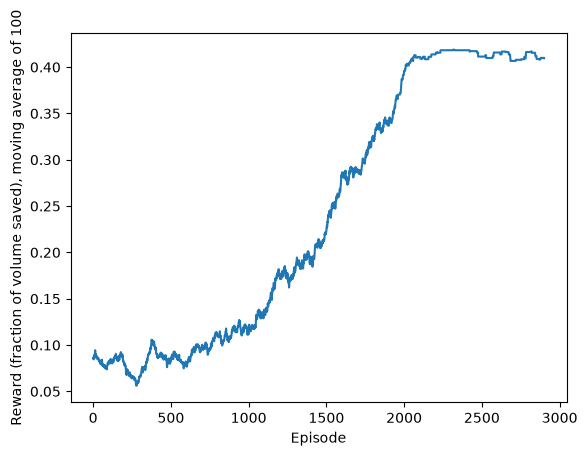

In [9]:
env_TSE = TrussStressEnv(nodes, ground_structure_bars, dofs, A, E, ff, sigma_lim=sigma_lim, disp_dof=disp_dof)

# episodes: ~3000 for this 13-bar ground structure (a few seconds); ~20000 for grid (3, 1), 22 bars
Q_TSE, rewards_TSE = train_TSE(env_TSE, episodes=3000, print_every=500)

plt.plot(np.convolve(rewards_TSE, np.ones(100) / 100, mode="valid"))
plt.xlabel("Episode")
plt.ylabel("Reward (fraction of volume saved), moving average of 100")
plt.show()

Stress limit max |sigma| <= 25.0 MPa

Step | Removed |   Nodes | max|sigma| (MPa) |   in |   u at dof 9 (mm) | Volume (m3)
--------------------------------------------------------------------------------------
   0 |       - |       - |           16.117 |   M2 |           -0.2567 |     0.06852
   1 |     M11 |   N3-N5 |           17.417 |   M2 |           -0.3065 |     0.06452
   2 |      M6 |   N1-N4 |           19.051 |   M2 |           -0.3801 |     0.05557
   3 |      M9 |   N2-N5 |           19.720 |   M2 |           -0.3733 |     0.04991
   4 |      M3 |   N0-N5 |           19.720 |   M2 |           -0.3733 |     0.03697   (+ dangling M12)
   5 |      M0 |   N0-N1 |           19.720 |   M2 |           -0.3733 |     0.03297

Stop: removing M2 (N0-N3) next would give max |sigma| = 35.355 MPa in M4 > 25.0 MPa

Final: 7 of 13 members, volume 0.03297 m3 (48.1% of ground structure)


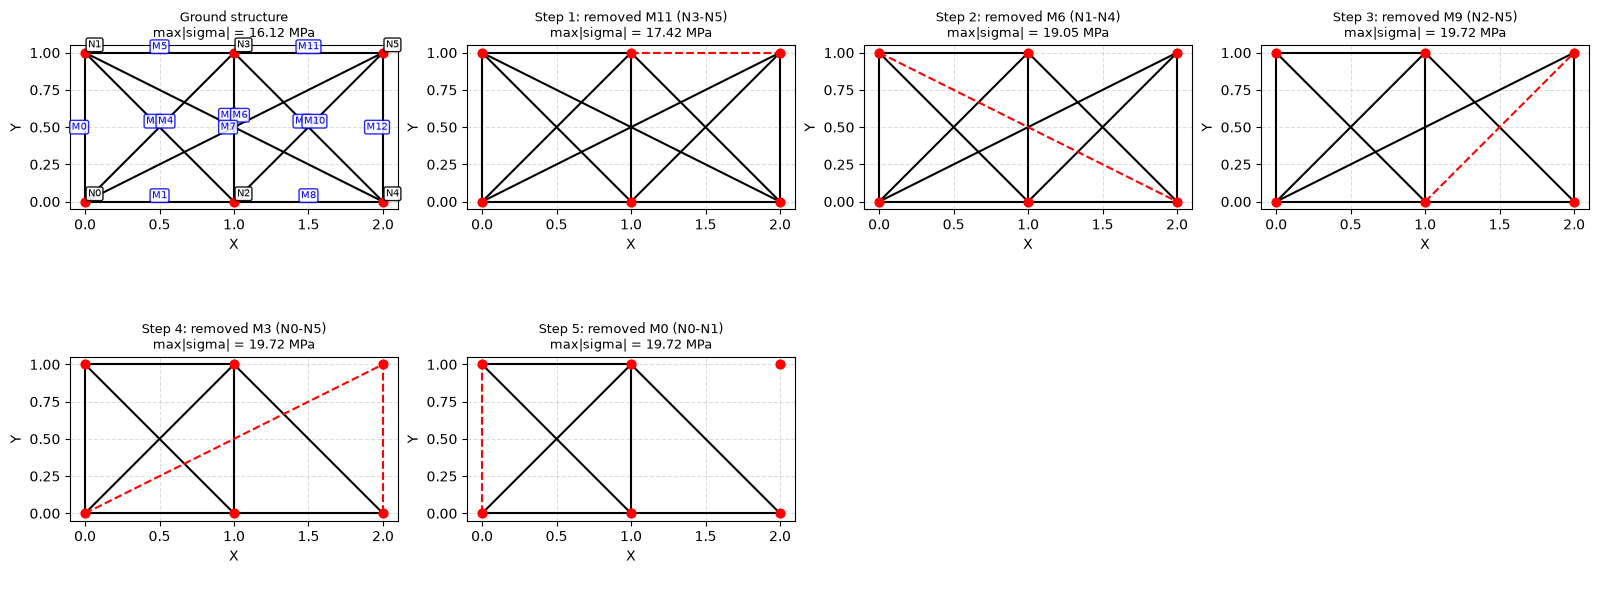

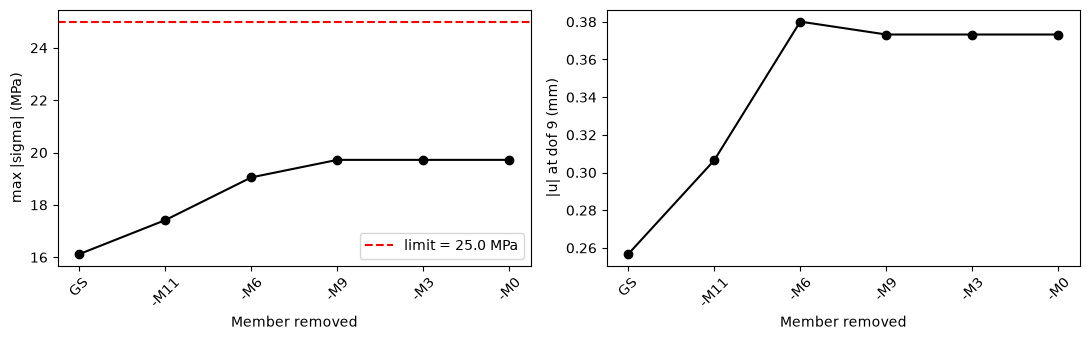


Exhaustive search: volume 0.03297 m3, members removed: ['M0', 'M3', 'M6', 'M9', 'M11', 'M12']


In [10]:
history_TSE = run_trained_TSE_agent(env_TSE, Q_TSE)

if env_TSE.n_bars <= 16:
    V_ex, s_ex = exhaustive_best(env_TSE)
    print(f"\nExhaustive search: volume {V_ex:.5f} m3, members removed: {[f'M{k}' for k in np.where(s_ex == 0)[0]]}")